In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("EDA libraries are ready!")

EDA libraries are ready!


In [2]:
np.random.seed(42)

n = 300

df = pd.DataFrame({
    "Shipment_ID": range(1001, 1001 + n),
    "City": np.random.choice(
        ["Chennai", "Dubai", "Mumbai", "Riyadh", "Dammam"], n
    ),
    "Distance_km": np.random.randint(10, 1200, n),
    "Warehouse_Load": np.random.randint(20, 101, n),
    "Shipping_Method": np.random.choice(
        ["Standard", "Express", "Same Day"], n
    ),
    "Shipping_Cost": np.random.randint(50, 1501, n),
    "Delivery_Days": np.random.randint(1, 11, n),
    "Status": np.random.choice(
        ["Delivered", "Delayed", "In Transit"], n,
        p=[0.65, 0.25, 0.10]
    )
})

df.head(10)

,Shipment_ID,City,Distance_km,Warehouse_Load,Shipping_Method,Shipping_Cost,Delivery_Days,Status
0,1001,Riyadh,1070,92,Same Day,491,8,Delivered
1,1002,Dammam,289,52,Express,78,1,Delivered
2,1003,Mumbai,506,96,Same Day,1182,9,Delivered
3,1004,Dammam,311,48,Standard,659,9,Delivered
4,1005,Dammam,190,32,Express,854,5,Delayed
5,1006,Dubai,616,65,Standard,124,10,Delayed
6,1007,Mumbai,1132,54,Same Day,887,4,Delivered
7,1008,Mumbai,709,25,Same Day,1219,6,Delayed
8,1009,Mumbai,1002,88,Same Day,177,7,Delivered
9,1010,Dammam,1149,66,Standard,91,5,Delivered


In [3]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 records:")
display(df.head())

print("\nDataset information:")
df.info()

Dataset shape: (300, 8)

Column names:
['Shipment_ID', 'City', 'Distance_km', 'Warehouse_Load', 'Shipping_Method', 'Shipping_Cost', 'Delivery_Days', 'Status']

First 5 records:


,Shipment_ID,City,Distance_km,Warehouse_Load,Shipping_Method,Shipping_Cost,Delivery_Days,Status
0,1001,Riyadh,1070,92,Same Day,491,8,Delivered
1,1002,Dammam,289,52,Express,78,1,Delivered
2,1003,Mumbai,506,96,Same Day,1182,9,Delivered
3,1004,Dammam,311,48,Standard,659,9,Delivered
4,1005,Dammam,190,32,Express,854,5,Delayed



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Shipment_ID      300 non-null    int64 
 1   City             300 non-null    object
 2   Distance_km      300 non-null    int64 
 3   Warehouse_Load   300 non-null    int64 
 4   Shipping_Method  300 non-null    object
 5   Shipping_Cost    300 non-null    int64 
 6   Delivery_Days    300 non-null    int64 
 7   Status           300 non-null    object
dtypes: int64(5), object(3)
memory usage: 18.9+ KB


In [4]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nUnique shipment IDs:", df["Shipment_ID"].nunique())

Missing values:
Shipment_ID        0
City               0
Distance_km        0
Warehouse_Load     0
Shipping_Method    0
Shipping_Cost      0
Delivery_Days      0
Status             0
dtype: int64

Duplicate rows: 0

Unique shipment IDs: 300


In [5]:
print("Numerical statistical summary:")
display(df.describe().round(2))

print("\nCategorical statistical summary:")
display(df.describe(include="object"))

print("\nDelivery status counts:")
print(df["Status"].value_counts())

Numerical statistical summary:


,Shipment_ID,Distance_km,Warehouse_Load,Shipping_Cost,Delivery_Days
count,300.00,300.00,300.00,300.00,300.00
mean,1150.50,670.15,58.90,782.50,5.42
std,86.75,341.65,24.45,435.46,2.90
min,1001.00,14.00,20.00,52.00,1.00
25%,1075.75,406.00,37.00,387.00,3.00
50%,1150.50,708.50,58.00,814.50,5.50
75%,1225.25,966.25,81.00,1164.25,8.00
max,1300.00,1198.00,100.00,1499.00,10.00



Categorical statistical summary:


,City,Shipping_Method,Status
count,300,300,300
unique,5,3,3
top,Riyadh,Same Day,Delivered
freq,74,109,206



Delivery status counts:
Status
Delivered     206
Delayed        68
In Transit     26
Name: count, dtype: int64


In [6]:
total_shipments = len(df)
delivered = (df["Status"] == "Delivered").sum()
delayed = (df["Status"] == "Delayed").sum()
in_transit = (df["Status"] == "In Transit").sum()

delivery_rate = delivered / total_shipments * 100
delay_rate = delayed / total_shipments * 100

print("Total Shipments:", total_shipments)
print("Delivered:", delivered)
print("Delayed:", delayed)
print("In Transit:", in_transit)
print(f"Delivered Rate: {delivery_rate:.2f}%")
print(f"Delayed Rate: {delay_rate:.2f}%")
print(f"Average Delivery Days: {df['Delivery_Days'].mean():.2f}")
print(f"Average Shipping Cost: {df['Shipping_Cost'].mean():.2f}")
print(f"Average Warehouse Load: {df['Warehouse_Load'].mean():.2f}%")

Total Shipments: 300
Delivered: 206
Delayed: 68
In Transit: 26
Delivered Rate: 68.67%
Delayed Rate: 22.67%
Average Delivery Days: 5.42
Average Shipping Cost: 782.50
Average Warehouse Load: 58.90%


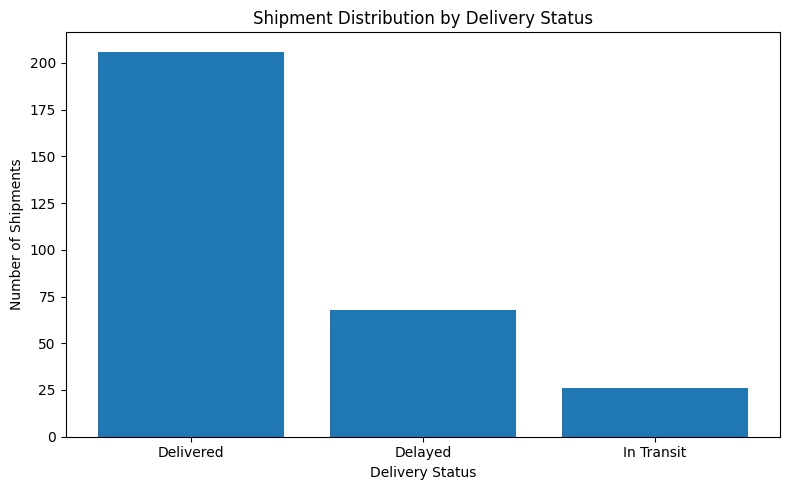

In [7]:
status_counts = df["Status"].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(status_counts.index, status_counts.values)
plt.title("Shipment Distribution by Delivery Status")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Shipments")
plt.tight_layout()
plt.savefig("1_delivery_status.png", dpi=300, bbox_inches="tight")
plt.show()

,Delivery_Days
City,
Riyadh,5.77
Mumbai,5.60
Dammam,5.40
Dubai,5.37
Chennai,4.94


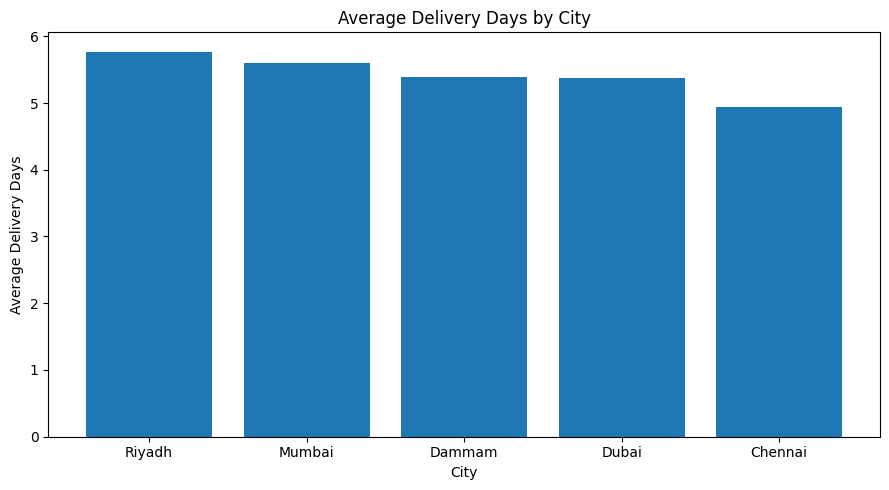

In [8]:
city_delivery = (
    df.groupby("City")["Delivery_Days"]
    .mean()
    .sort_values(ascending=False)
)

display(city_delivery.round(2))

plt.figure(figsize=(9, 5))
plt.bar(city_delivery.index, city_delivery.values)
plt.title("Average Delivery Days by City")
plt.xlabel("City")
plt.ylabel("Average Delivery Days")
plt.tight_layout()
plt.savefig("2_delivery_days_by_city.png", dpi=300, bbox_inches="tight")
plt.show()

,Shipping_Cost
Shipping_Method,
Standard,813.77
Express,768.87
Same Day,766.83


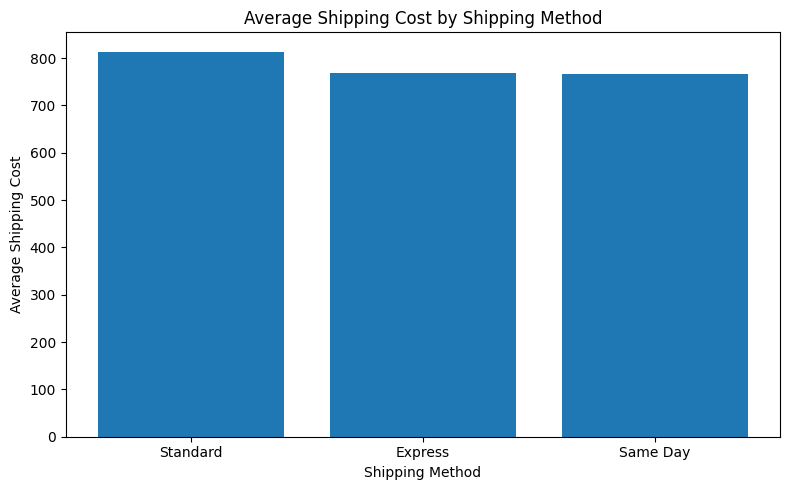

In [9]:
method_cost = (
    df.groupby("Shipping_Method")["Shipping_Cost"]
    .mean()
    .sort_values(ascending=False)
)

display(method_cost.round(2))

plt.figure(figsize=(8, 5))
plt.bar(method_cost.index, method_cost.values)
plt.title("Average Shipping Cost by Shipping Method")
plt.xlabel("Shipping Method")
plt.ylabel("Average Shipping Cost")
plt.tight_layout()
plt.savefig("3_shipping_cost_by_method.png", dpi=300, bbox_inches="tight")
plt.show()

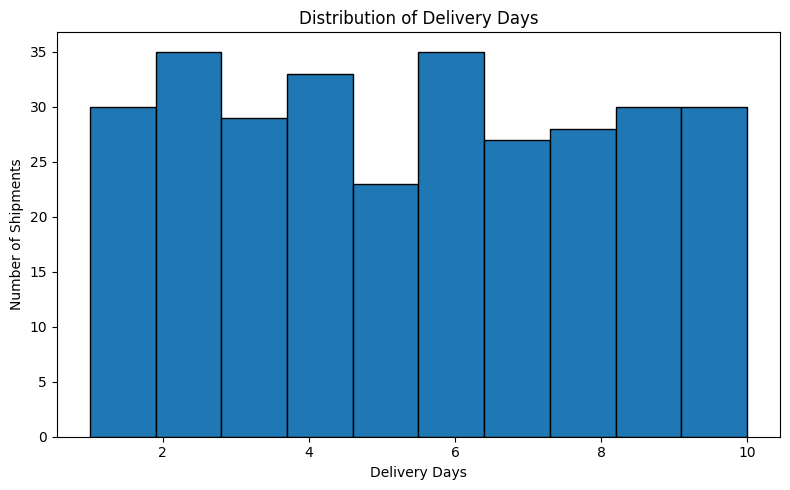

In [10]:
plt.figure(figsize=(8, 5))
plt.hist(df["Delivery_Days"], bins=10, edgecolor="black")
plt.title("Distribution of Delivery Days")
plt.xlabel("Delivery Days")
plt.ylabel("Number of Shipments")
plt.tight_layout()
plt.savefig("4_delivery_time_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

,Warehouse_Load
Status,
Delivered,59.26
Delayed,58.79
In Transit,56.27


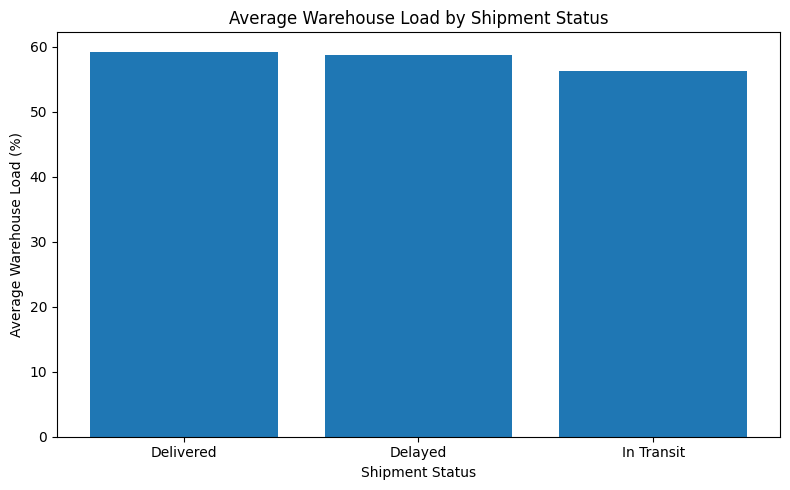

In [11]:
load_status = (
    df.groupby("Status")["Warehouse_Load"]
    .mean()
    .sort_values(ascending=False)
)

display(load_status.round(2))

plt.figure(figsize=(8, 5))
plt.bar(load_status.index, load_status.values)
plt.title("Average Warehouse Load by Shipment Status")
plt.xlabel("Shipment Status")
plt.ylabel("Average Warehouse Load (%)")
plt.tight_layout()
plt.savefig("5_warehouse_load_by_status.png", dpi=300, bbox_inches="tight")
plt.show()

,Distance_km,Warehouse_Load,Shipping_Cost,Delivery_Days
Distance_km,1.00,0.05,0.05,0.02
Warehouse_Load,0.05,1.00,-0.02,0.04
Shipping_Cost,0.05,-0.02,1.00,0.01
Delivery_Days,0.02,0.04,0.01,1.00


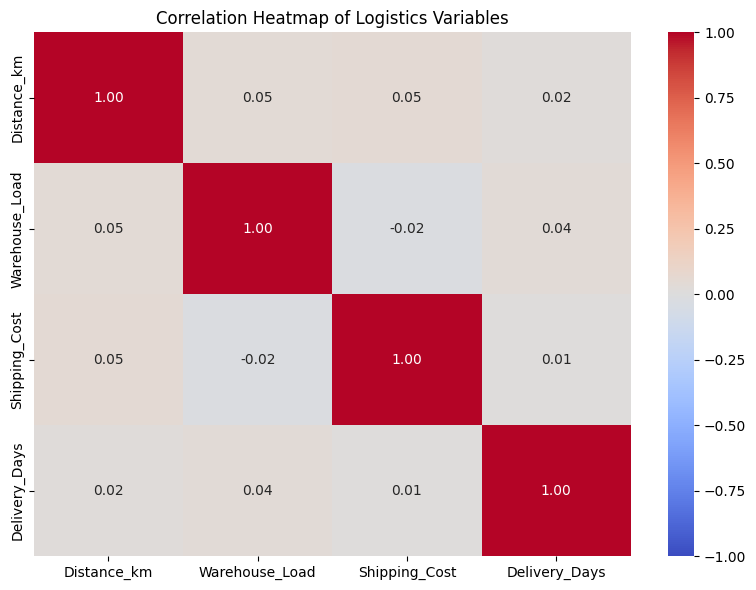

In [12]:
numeric_df = df[
    ["Distance_km", "Warehouse_Load",
     "Shipping_Cost", "Delivery_Days"]
]

correlation = numeric_df.corr()

display(correlation.round(2))

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)
plt.title("Correlation Heatmap of Logistics Variables")
plt.tight_layout()
plt.savefig("6_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

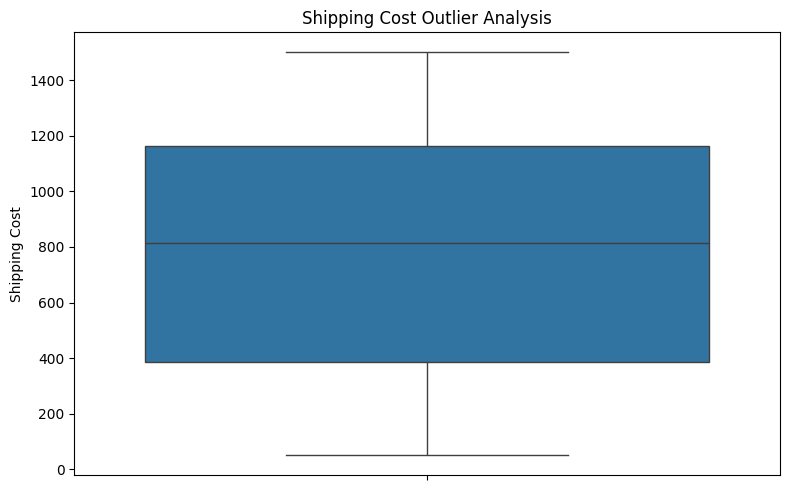

Potential shipping cost outliers: 0


,Shipment_ID,City,Distance_km,Warehouse_Load,Shipping_Method,Shipping_Cost,Delivery_Days,Status


In [13]:
plt.figure(figsize=(8, 5))
sns.boxplot(y=df["Shipping_Cost"])
plt.title("Shipping Cost Outlier Analysis")
plt.ylabel("Shipping Cost")
plt.tight_layout()
plt.savefig("7_shipping_cost_boxplot.png", dpi=300, bbox_inches="tight")
plt.show()

Q1 = df["Shipping_Cost"].quantile(0.25)
Q3 = df["Shipping_Cost"].quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["Shipping_Cost"] < lower_limit)
    | (df["Shipping_Cost"] > upper_limit)
]

print("Potential shipping cost outliers:", len(outliers))
display(outliers.head(10))

Status,Delayed,Delivered,In Transit
Shipping_Method,,,
Express,22,64,9
Same Day,23,74,12
Standard,23,68,5


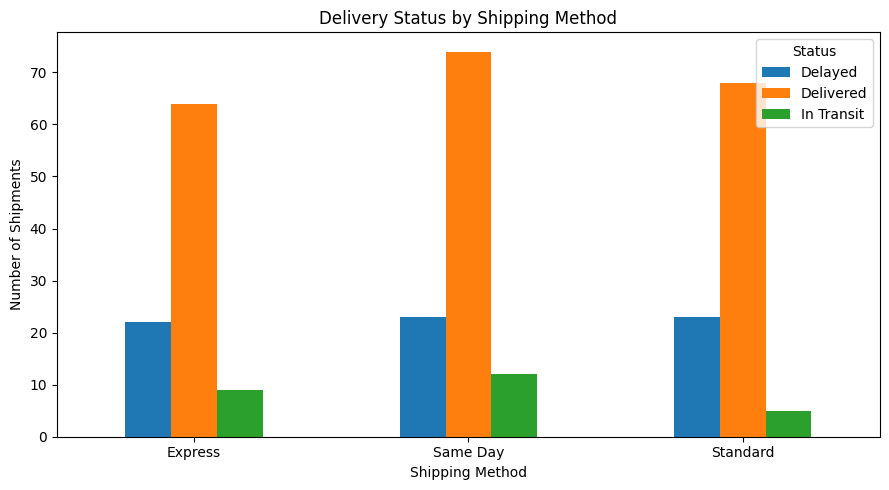

In [14]:
status_method = pd.crosstab(
    df["Shipping_Method"],
    df["Status"]
)

display(status_method)

status_method.plot(kind="bar", figsize=(9, 5))
plt.title("Delivery Status by Shipping Method")
plt.xlabel("Shipping Method")
plt.ylabel("Number of Shipments")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("8_status_by_shipping_method.png", dpi=300, bbox_inches="tight")
plt.show()

In [15]:
status_percent = pd.crosstab(
    df["Shipping_Method"],
    df["Status"],
    normalize="index"
) * 100

display(status_percent.round(2))

Status,Delayed,Delivered,In Transit
Shipping_Method,,,
Express,23.16,67.37,9.47
Same Day,21.10,67.89,11.01
Standard,23.96,70.83,5.21


In [16]:
df.to_csv("logistics_eda_dataset.csv", index=False)

print("Dataset exported successfully!")

Dataset exported successfully!


In [17]:
city_means = df.groupby("City")["Delivery_Days"].mean()
slowest_city = city_means.idxmax()
slowest_city_days = city_means.max()

method_means = df.groupby("Shipping_Method")["Shipping_Cost"].mean()
costliest_method = method_means.idxmax()
costliest_method_cost = method_means.max()

highest_load_status = load_status.idxmax()
highest_load_value = load_status.max()

report = f"""
EXPLORATORY DATA ANALYSIS OF LOGISTICS PERFORMANCE

1. OBJECTIVE
Explore shipment data to identify patterns in delivery duration,
shipping costs, warehouse workload, and delivery status.

2. DATASET
Total records: {len(df)}
Cities represented: {df['City'].nunique()}
Shipping methods: {df['Shipping_Method'].nunique()}
Missing values: {df.isnull().sum().sum()}
Duplicate rows: {df.duplicated().sum()}

Note: The dataset is simulated for educational purposes.

3. KEY PERFORMANCE INDICATORS
Delivered: {delivered}
Delayed: {delayed}
In Transit: {in_transit}
Delivered rate: {delivery_rate:.2f}%
Delayed rate: {delay_rate:.2f}%
Average delivery duration: {df['Delivery_Days'].mean():.2f} days
Average shipping cost: {df['Shipping_Cost'].mean():.2f}

4. KEY FINDINGS
- {slowest_city} has the highest average delivery duration
  in this simulated sample ({slowest_city_days:.2f} days).
- {costliest_method} has the highest average shipping cost
  ({costliest_method_cost:.2f}) among the methods.
- {highest_load_status} shipments have the highest average
  warehouse load ({highest_load_value:.2f}%).
- Correlations and potential shipping cost outliers were
  examined to explore relationships and unusual observations.

5. RECOMMENDATIONS
- Monitor delivery performance by city and shipping method.
- Investigate unusual shipping charges before making adjustments.
- Review warehouse workload alongside actual delay records.
- Repeat the analysis using validated historical operational data.
- Use more representative data to test whether observed patterns
  persist over time.

6. LIMITATIONS
The dataset is randomly generated. The findings describe this
sample only and must not be treated as actual company performance.
The generated variables do not establish causal relationships.

TOOLS
Python, Pandas, NumPy, Matplotlib, Seaborn and Google Colab.
"""

with open("EDA_Business_Insights_Report.txt", "w", encoding="utf-8") as f:
    f.write(report)

print(report)
print("Report saved successfully!")


EXPLORATORY DATA ANALYSIS OF LOGISTICS PERFORMANCE

1. OBJECTIVE
Explore shipment data to identify patterns in delivery duration,
shipping costs, warehouse workload, and delivery status.

2. DATASET
Total records: 300
Cities represented: 5
Shipping methods: 3
Missing values: 0
Duplicate rows: 0

Note: The dataset is simulated for educational purposes.

3. KEY PERFORMANCE INDICATORS
Delivered: 206
Delayed: 68
In Transit: 26
Delivered rate: 68.67%
Delayed rate: 22.67%
Average delivery duration: 5.42 days
Average shipping cost: 782.50

4. KEY FINDINGS
- Riyadh has the highest average delivery duration
  in this simulated sample (5.77 days).
- Standard has the highest average shipping cost
  (813.77) among the methods.
- Delivered shipments have the highest average
  warehouse load (59.26%).
- Correlations and potential shipping cost outliers were
  examined to explore relationships and unusual observations.

5. RECOMMENDATIONS
- Monitor delivery performance by city and shipping method.
-

In [18]:
import zipfile
import os

project_files = [
    "logistics_eda_dataset.csv",
    "1_delivery_status.png",
    "2_delivery_days_by_city.png",
    "3_shipping_cost_by_method.png",
    "4_delivery_time_distribution.png",
    "5_warehouse_load_by_status.png",
    "6_correlation_heatmap.png",
    "7_shipping_cost_boxplot.png",
    "8_status_by_shipping_method.png",
    "EDA_Business_Insights_Report.txt"
]

with zipfile.ZipFile("Logistics_EDA_Project_Files.zip", "w") as z:
    for file in project_files:
        if os.path.exists(file):
            z.write(file)

print("Project ZIP created successfully!")

Project ZIP created successfully!


In [19]:
from google.colab import files

files.download("Logistics_EDA_Project_Files.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>